# Passos Mágicos — Análise dos Indicadores e Alerta de Risco de Defasagem

Análise da base PEDE (2022 a 2024) da Associação Passos Mágicos, respondendo às perguntas do Datathon, e construção de um modelo que estima a probabilidade de cada aluno estar defasado no ano seguinte.

**Convenção usada em todo o notebook:** a defasagem é a diferença entre a fase do aluno no programa e a fase ideal para a sua idade escolar. **Valores negativos indicam aluno atrasado**; zero ou positivo, aluno adequado ou adiantado.

# 1. Bibliotecas e carregamento

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

from utils.preparacao import carrega_base, pares_ano_seguinte, INDICADORES, ORDEM_PEDRAS

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
base = carrega_base('data/BASE DE DADOS PEDE 2024 - DATATHON.xlsx')
print(base.shape)
base.head()

(3030, 17)


,RA,ANO,FASE,IDADE,GENERO,PEDRA,INDE,DEFASAGEM,IAN,IDA,IEG,IAA,IPS,IPP,IPV,NIVEL_DEFASAGEM,DEFASADO
0,RA-1,2022,7,19,Feminino,Quartzo,5.783,-1,5.0,4.0,4.1,8.3,5.6,NaN,7.278,Moderada,1
1,RA-2,2022,7,17,Feminino,Ametista,7.055,0,10.0,6.8,5.2,8.8,6.3,NaN,6.778,Sem defasagem,0
2,RA-3,2022,7,17,Feminino,Ágata,6.591,0,10.0,5.6,7.9,0.0,5.6,NaN,7.556,Sem defasagem,0
3,RA-4,2022,7,17,Masculino,Quartzo,5.951,0,10.0,5.0,4.5,8.8,5.6,NaN,5.278,Sem defasagem,0
4,RA-5,2022,7,17,Feminino,Ametista,7.427,0,10.0,5.2,8.6,7.9,5.6,NaN,7.389,Sem defasagem,0


## 1.1 O que a padronização resolve

As três abas da planilha têm diferenças que precisam ser tratadas antes de juntar os anos (código em `utils/preparacao.py`):

- **Nomes de colunas diferentes:** `Defas` (2022) e `Defasagem` (2023 e 2024); `INDE 22`, `INDE 2023` e `INDE 2024`; o mesmo para a pedra.
- **Fase em formatos diferentes:** número em 2022, `FASE 3` em 2023 e código de turma como `3B` em 2024. Tudo vira número, com `ALFA` = 0.
- **Idade inconsistente:** em 2023 parte das idades foi gravada como data. A idade é recalculada a partir do ano de nascimento.
- **Textos em colunas numéricas,** como `INCLUIR`, viram nulo.
- **IPP não existe em 2022.**

In [3]:
base.groupby('ANO')[INDICADORES + ['INDE', 'DEFASAGEM']].count()

,IAN,IDA,IEG,IAA,IPS,IPP,IPV,INDE,DEFASAGEM
ANO,,,,,,,,,
2022,860,860,860,860,860,0,860,860,860
2023,1014,937,938,951,945,938,938,931,1014
2024,1156,1055,1156,1054,1054,1054,1054,1054,1156


# 2. Respostas às perguntas do Datathon

## Pergunta 1 — Adequação do nível (IAN): perfil de defasagem e evolução

NIVEL_DEFASAGEM,Sem defasagem,Moderada,Severa
ANO,,,
2022,30.1,66.6,3.3
2023,45.6,53.1,1.4
2024,53.8,45.9,0.3


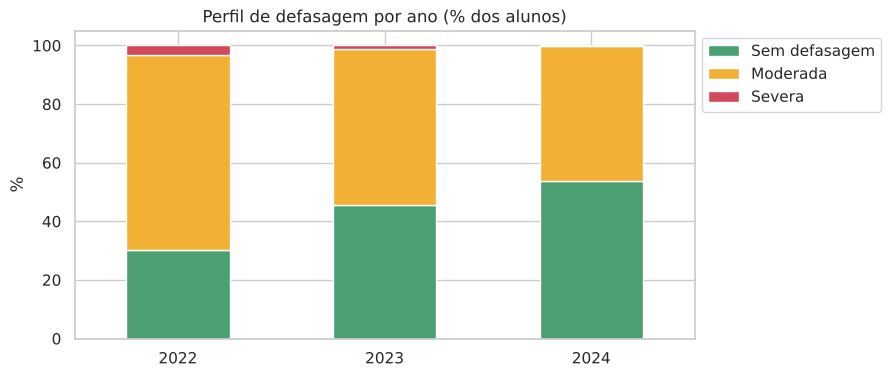

In [4]:
perfil = (pd.crosstab(base['ANO'], base['NIVEL_DEFASAGEM'], normalize='index')
            [['Sem defasagem', 'Moderada', 'Severa']] * 100).round(1)
display(perfil)

perfil.plot(kind='bar', stacked=True, figsize=(8, 4), color=['#4C9F70', '#F2B134', '#D1495B'])
plt.title('Perfil de defasagem por ano (% dos alunos)')
plt.ylabel('%'); plt.xlabel(''); plt.xticks(rotation=0); plt.legend(bbox_to_anchor=(1, 1))
plt.show()

**Leitura:** a defasagem diminuiu ano a ano. A parcela de alunos sem defasagem passou de cerca de 30% em 2022 para 54% em 2024, e a defasagem severa ficou próxima de zero. Ainda assim, quase metade dos alunos segue com defasagem moderada.

## Pergunta 2 — Desempenho acadêmico (IDA) ao longo de anos e fases

ANO
2022    6.09
2023    6.66
2024    6.35
Name: IDA, dtype: float64

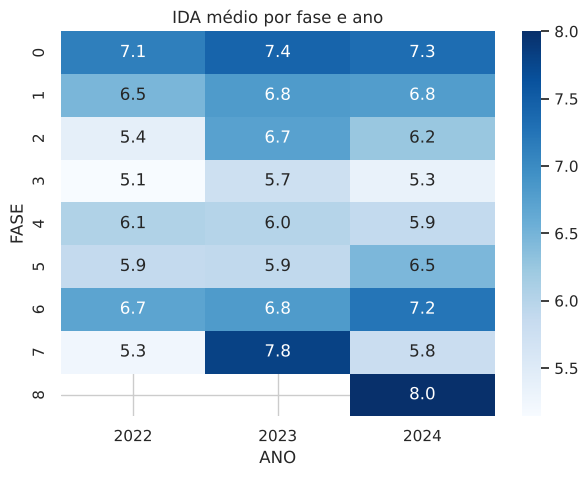

In [5]:
display(base.groupby('ANO')['IDA'].mean().round(2))

ida_fase = base.pivot_table(values='IDA', index='FASE', columns='ANO', aggfunc='mean')
plt.figure(figsize=(7, 5))
sns.heatmap(ida_fase, annot=True, fmt='.1f', cmap='Blues')
plt.title('IDA médio por fase e ano')
plt.show()

**Leitura:** o IDA médio subiu de 2022 para 2023 e recuou em 2024, sem uma tendência clara de melhora. Por fase, o desempenho é mais alto no início (ALFA e fase 1), e a fase 3 tem o menor IDA médio nos três anos. É o ponto do ciclo que mais pede reforço acadêmico.

## Pergunta 3 — Engajamento (IEG) se relaciona com desempenho (IDA) e ponto de virada (IPV)?

,IEG,IDA,IPV
IEG,1.00,0.54,0.56
IDA,0.54,1.00,0.56
IPV,0.56,0.56,1.00


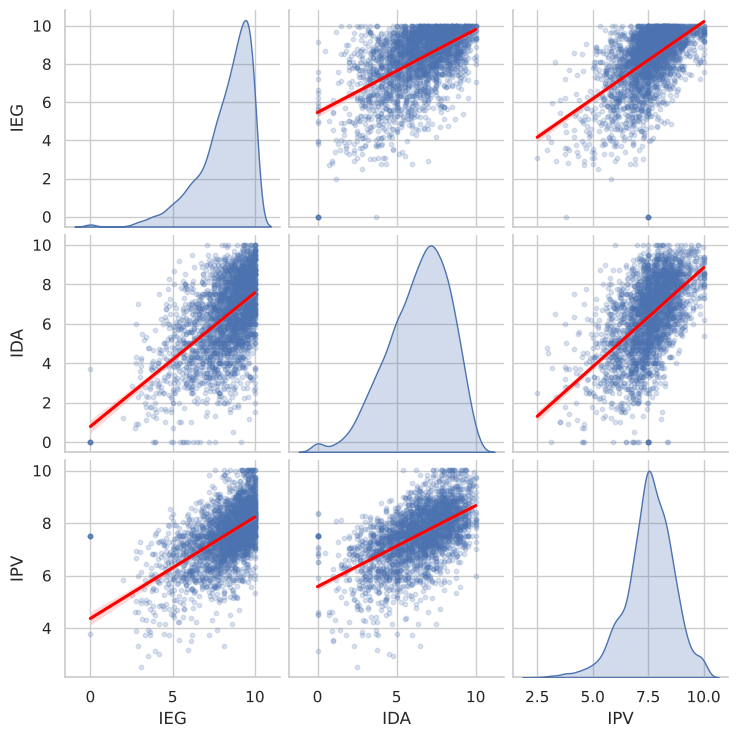

In [6]:
display(base[['IEG', 'IDA', 'IPV']].corr().round(2))
sns.pairplot(base[['IEG', 'IDA', 'IPV']].dropna(), kind='reg', diag_kind='kde',
             plot_kws={'scatter_kws': {'alpha': 0.2, 's': 10}, 'line_kws': {'color': 'red'}})
plt.show()

**Leitura:** sim. O engajamento tem correlação moderada e positiva (cerca de 0,55) tanto com o IDA quanto com o IPV. Alunos mais engajados tendem a ter melhor desempenho e a se aproximar do ponto de virada, mas a relação está longe de ser determinística.

## Pergunta 4 — A autoavaliação (IAA) é coerente com desempenho (IDA) e engajamento (IEG)?

,IAA,IDA,IEG
IAA,1.00,0.12,0.13
IDA,0.12,1.00,0.54
IEG,0.13,0.54,1.00


IAA médio: 7.92 | IDA médio: 6.38 | diferença média IAA - IDA: 1.55


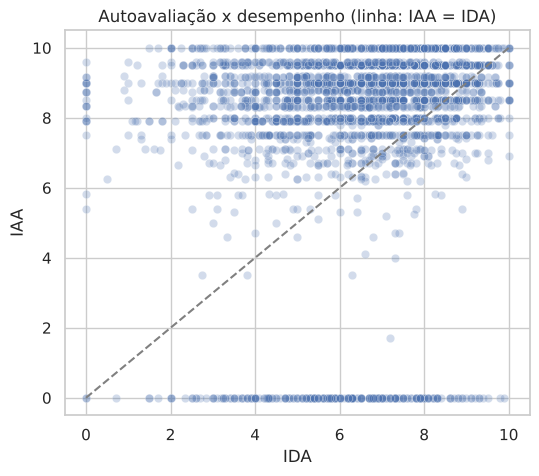

In [7]:
display(base[['IAA', 'IDA', 'IEG']].corr().round(2))
print(f"IAA médio: {base['IAA'].mean():.2f} | IDA médio: {base['IDA'].mean():.2f} | "
      f"diferença média IAA - IDA: {(base['IAA'] - base['IDA']).mean():.2f}")

plt.figure(figsize=(6, 5))
sns.scatterplot(data=base, x='IDA', y='IAA', alpha=0.25)
plt.plot([0, 10], [0, 10], '--', color='gray')
plt.title('Autoavaliação x desempenho (linha: IAA = IDA)')
plt.show()

**Leitura:** pouco coerente. A correlação do IAA com IDA e IEG é próxima de zero (cerca de 0,1), e os alunos se avaliam, em média, 1,5 ponto acima do desempenho medido. A autoavaliação reflete pouco a situação real, o que sugere usá-la como ponto de conversa com o aluno, e não como sinal de desempenho.

## Pergunta 5 — Padrões psicossociais (IPS) antecedem quedas de desempenho ou engajamento?

In [8]:
def variacao_ano_seguinte(coluna):
    seguinte = (base[['RA', 'ANO', coluna]].assign(ANO=lambda d: d['ANO'] - 1)
                .rename(columns={coluna: f'{coluna}_PROX'}))
    df = base.merge(seguinte, on=['RA', 'ANO'])
    df['VARIACAO'] = df[f'{coluna}_PROX'] - df[coluna]
    df['IPS_BAIXO'] = df['IPS'] < df['IPS'].quantile(0.25)
    return df

for coluna in ['IDA', 'IEG']:
    df = variacao_ano_seguinte(coluna)
    queda = df.groupby('IPS_BAIXO')['VARIACAO'].apply(lambda s: (s < -1).mean() * 100).round(1)
    print(f"{coluna}: correlação IPS x variação no ano seguinte = {df[['IPS', 'VARIACAO']].corr().iloc[0, 1]:.2f} | "
          f"% com queda > 1 ponto: IPS baixo = {queda[True]}%, demais = {queda[False]}%")

IDA: correlação IPS x variação no ano seguinte = 0.12 | % com queda > 1 ponto: IPS baixo = 35.7%, demais = 25.0%
IEG: correlação IPS x variação no ano seguinte = 0.16 | % com queda > 1 ponto: IPS baixo = 32.1%, demais = 18.9%


**Leitura:** há um sinal, mas fraco. Alunos no quarto inferior de IPS têm queda de mais de 1 ponto no ano seguinte com mais frequência (cerca de 36% contra 25% no IDA, e 32% contra 19% no IEG). A correlação, porém, é baixa. O IPS ajuda a priorizar acompanhamento, mas sozinho não prevê quem vai cair.

## Pergunta 6 — As avaliações psicopedagógicas (IPP) confirmam a defasagem do IAN?

In [9]:
display(base.groupby('NIVEL_DEFASAGEM')['IPP'].agg(['mean', 'count']).round(2))
print(f"Correlação IPP x IAN: {base[['IPP', 'IAN']].corr().iloc[0, 1]:.2f}")

,mean,count
NIVEL_DEFASAGEM,,
Moderada,7.46,1067
Sem defasagem,7.68,908
Severa,7.01,17


Correlação IPP x IAN: 0.12


**Leitura:** só parcialmente. O IPP médio é um pouco menor nos alunos com defasagem (7,0 na severa e 7,5 na moderada, contra 7,7 sem defasagem), mas a correlação com o IAN é fraca (cerca de 0,1). A avaliação psicopedagógica capta algo diferente do atraso escolar e não deve ser lida como confirmação dele.

## Pergunta 7 — O que mais influencia o ponto de virada (IPV)?

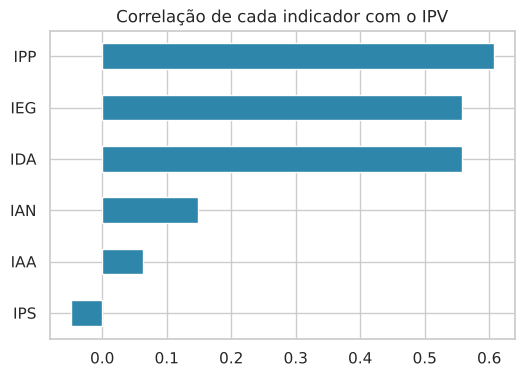

In [10]:
corr_ipv = base[INDICADORES].corr()['IPV'].drop('IPV').sort_values()
corr_ipv.plot(kind='barh', figsize=(6, 4), color='#2E86AB')
plt.title('Correlação de cada indicador com o IPV')
plt.show()

**Leitura:** o IPV anda junto com o IPP (cerca de 0,6), o IDA e o IEG (cerca de 0,55). Autoavaliação (IAA), aspectos psicossociais (IPS) e adequação de nível (IAN) quase não se relacionam com ele. O ponto de virada está ligado a desempenho, engajamento e à leitura psicopedagógica.

## Pergunta 8 — Quais combinações de indicadores elevam mais o INDE?

In [11]:
dados_inde = base.dropna(subset=['INDE'] + INDICADORES)
regressao = LinearRegression().fit(dados_inde[INDICADORES], dados_inde['INDE'])
pesos = pd.Series(regressao.coef_, index=INDICADORES).round(3).sort_values(ascending=False)
display(pesos.to_frame('peso no INDE'))
print(f"R² = {regressao.score(dados_inde[INDICADORES], dados_inde['INDE']):.4f}")

,peso no INDE
IDA,0.200
IEG,0.200
IPV,0.199
IAN,0.100
IAA,0.100
IPS,0.100
IPP,0.100


R² = 1.0000


**Leitura:** o INDE é uma **média ponderada fixa** dos indicadores (R² = 1). IDA, IEG e IPV pesam 20% cada; IAN, IAA, IPS e IPP, 10% cada (dados de 2023 e 2024, que têm todos os indicadores).

Por isso, a combinação que mais eleva o INDE é **desempenho + engajamento + ponto de virada**: um ponto a mais em qualquer um deles vale o dobro de um ponto em IPS ou IPP. Para a ONG, isso significa que ações de engajamento têm efeito duplo, já que o IEG pesa diretamente e se relaciona com IDA e IPV.

## Pergunta 10 — Os indicadores mostram melhora consistente ao longo do ciclo?

In [12]:
display(base.groupby('ANO')[['INDE', 'IDA', 'IEG', 'IPV']].mean().round(2))

pedras = (pd.crosstab(base['ANO'], base['PEDRA'], normalize='index')[ORDEM_PEDRAS] * 100).round(1)
display(pedras)

# Mesmos alunos acompanhados de 2022 a 2024
coorte = (base[base['ANO'] == 2022][['RA', 'INDE', 'PEDRA']]
          .merge(base[base['ANO'] == 2024][['RA', 'INDE', 'PEDRA']], on='RA', suffixes=('_2022', '_2024')))
ordem = {pedra: i for i, pedra in enumerate(ORDEM_PEDRAS)}
subiu = (coorte['PEDRA_2024'].map(ordem) > coorte['PEDRA_2022'].map(ordem)).mean() * 100
print(f"Coorte 2022-2024: {len(coorte)} alunos | INDE médio {coorte['INDE_2022'].mean():.2f} -> {coorte['INDE_2024'].mean():.2f} | "
      f"{subiu:.0f}% subiram de pedra")

,INDE,IDA,IEG,IPV
ANO,,,,
2022,7.04,6.09,7.89,7.25
2023,7.34,6.66,8.70,8.03
2024,7.40,6.35,7.37,7.35


PEDRA,Quartzo,Ágata,Ametista,Topázio
ANO,,,,
2022,15.3,29.1,40.5,15.1
2023,7.7,26.4,40.9,24.9
2024,10.6,21.3,37.1,30.9


Coorte 2022-2024: 472 alunos | INDE médio 7.37 -> 7.38 | 28% subiram de pedra


**Leitura:** a melhora não é consistente em todos os indicadores. A distribuição de pedras melhorou (Topázio passou de 15% para 31% dos alunos), mas o INDE médio ficou praticamente estável, e IEG e IPV subiram em 2023 e voltaram em 2024. Nos mesmos alunos acompanhados de 2022 a 2024, o INDE ficou estável e cerca de 28% subiram de pedra.

O ganho mais claro do programa está na **redução da defasagem** (pergunta 1). Nos indicadores de desempenho e engajamento, não há evidência de melhora contínua no período.

## Pergunta 11 — Insights adicionais: onde a defasagem se concentra

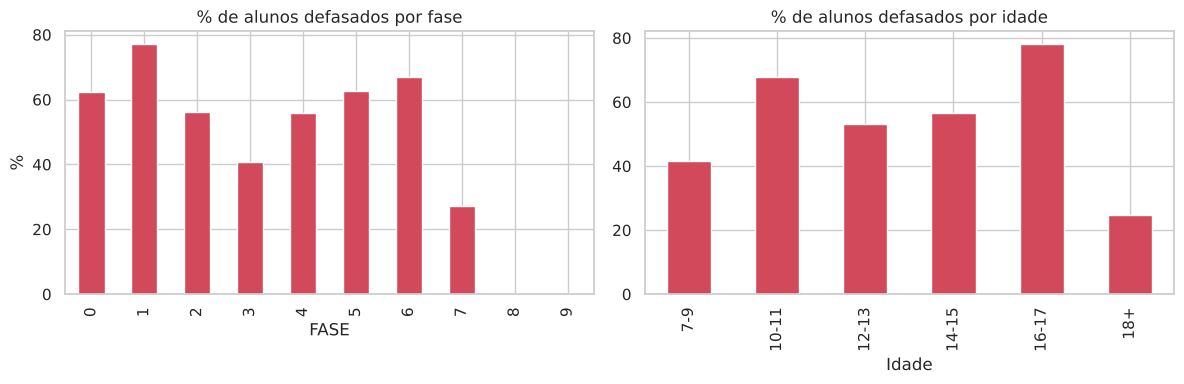

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
base.groupby('FASE')['DEFASADO'].mean().mul(100).plot(kind='bar', ax=eixos[0], color='#D1495B')
eixos[0].set_title('% de alunos defasados por fase'); eixos[0].set_ylabel('%')
faixas = pd.cut(base['IDADE'], [6, 9, 11, 13, 15, 17, 30], labels=['7-9', '10-11', '12-13', '14-15', '16-17', '18+'])
base.groupby(faixas, observed=True)['DEFASADO'].mean().mul(100).plot(kind='bar', ax=eixos[1], color='#D1495B')
eixos[1].set_title('% de alunos defasados por idade'); eixos[1].set_xlabel('Idade')
plt.tight_layout(); plt.show()

**Leitura:** a defasagem se concentra na fase 1 e nos alunos de 16 e 17 anos, ou seja, na entrada no programa e no fim do ensino médio. Esses dois momentos são candidatos naturais a reforço: nivelamento para quem entra e acompanhamento intensivo para quem está perto de concluir a escola.

# 3. Pergunta 9 — Modelo de alerta de risco de defasagem

## 3.1 Definição do problema

O objetivo é **antecipar** o risco, não descrever o presente. Por isso, o modelo usa os indicadores de um ano para prever a situação do aluno **no ano seguinte**:

- **Alvo:** o aluno estará defasado (defasagem < 0) no ano seguinte?
- **Variáveis:** indicadores do ano atual (IAN, IDA, IEG, IAA, IPS, IPV), idade e fase.
- **Fora do modelo:**
  - **INDE e pedra,** que são combinações dos próprios indicadores;
  - **IPP,** que não existe em 2022, primeiro ano de treino.

O IAN do ano atual entra porque é conhecido no momento da previsão: saber que o aluno já está defasado hoje é informação legítima para prever o ano seguinte.

**Validação temporal:** o modelo é treinado com a passagem 2022 → 2023 e testado com 2023 → 2024. É a situação real de uso: aprender com o passado para prever um ano que o modelo nunca viu.

In [14]:
pares = pares_ano_seguinte(base)
VARIAVEIS = ['IAN', 'IDA', 'IEG', 'IAA', 'IPS', 'IPV', 'IDADE', 'FASE']

treino = pares[pares['ANO'] == 2022]
teste = pares[pares['ANO'] == 2023]

print(f"Treino (2022 -> 2023): {len(treino)} alunos | {treino['DEFASADO_PROX'].mean():.0%} defasados no ano seguinte")
print(f"Teste  (2023 -> 2024): {len(teste)} alunos | {teste['DEFASADO_PROX'].mean():.0%} defasados no ano seguinte")

Treino (2022 -> 2023): 600 alunos | 61% defasados no ano seguinte
Teste  (2023 -> 2024): 765 alunos | 40% defasados no ano seguinte


## 3.2 Referência: repetir a situação atual

Antes do modelo, uma regra simples: "quem está defasado hoje estará defasado no ano que vem". Se o modelo não superar essa regra, não vale a pena usá-lo.

In [15]:
regra_simples = (teste['DEFASAGEM'] < 0).astype(int)
print(f"AUC da regra simples: {roc_auc_score(teste['DEFASADO_PROX'], regra_simples):.3f}")
print(classification_report(teste['DEFASADO_PROX'], regra_simples, target_names=['Adequado', 'Defasado']))

AUC da regra simples: 0.677
              precision    recall  f1-score   support

    Adequado       0.77      0.63      0.69       457
    Defasado       0.57      0.73      0.64       308

    accuracy                           0.67       765
   macro avg       0.67      0.68      0.66       765
weighted avg       0.69      0.67      0.67       765



## 3.3 Modelo

Gradient Boosting (`HistGradientBoostingClassifier`): aceita valores nulos sem imputação e captura relações não lineares entre idade e fase, que definem a fase ideal do aluno. Não foi usado balanceamento (SMOTE), porque as classes já são equilibradas (cerca de 40% a 60% de defasados) e o balanceamento distorceria as probabilidades, que são a saída principal para a ONG.

AUC: 0.876
Precisão média (AP): 0.817
              precision    recall  f1-score   support

    Adequado       0.83      0.82      0.82       457
    Defasado       0.74      0.75      0.74       308

    accuracy                           0.79       765
   macro avg       0.78      0.78      0.78       765
weighted avg       0.79      0.79      0.79       765



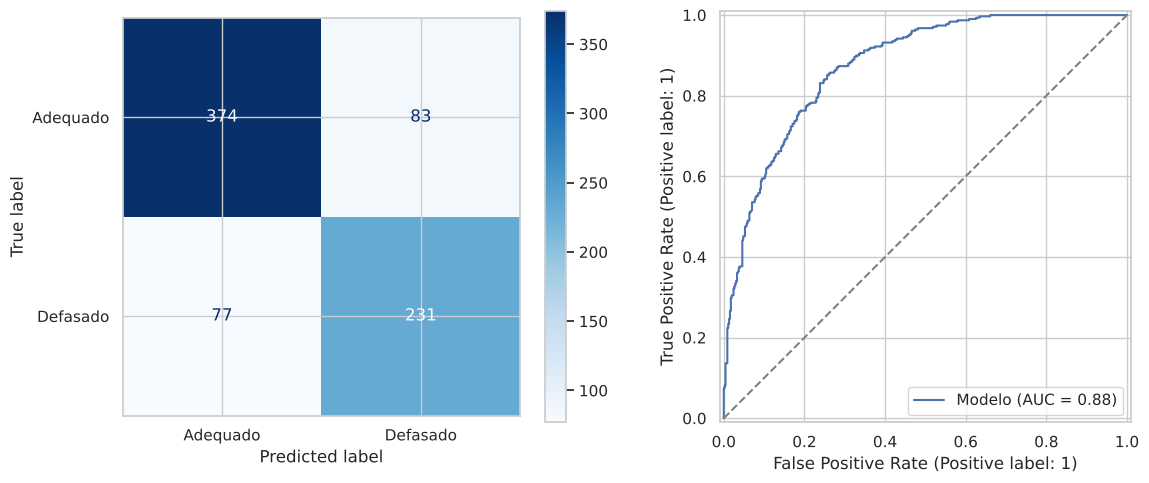

In [16]:
modelo = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)
modelo.fit(treino[VARIAVEIS], treino['DEFASADO_PROX'])

prob_teste = modelo.predict_proba(teste[VARIAVEIS])[:, 1]
print(f"AUC: {roc_auc_score(teste['DEFASADO_PROX'], prob_teste):.3f}")
print(f"Precisão média (AP): {average_precision_score(teste['DEFASADO_PROX'], prob_teste):.3f}")
print(classification_report(teste['DEFASADO_PROX'], prob_teste >= 0.5, target_names=['Adequado', 'Defasado']))

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(teste['DEFASADO_PROX'], prob_teste >= 0.5,
                                        display_labels=['Adequado', 'Defasado'], cmap='Blues', ax=eixos[0])
RocCurveDisplay.from_predictions(teste['DEFASADO_PROX'], prob_teste, name='Modelo', ax=eixos[1])
eixos[1].plot([0, 1], [0, 1], '--', color='gray')
plt.tight_layout(); plt.show()

## 3.4 O modelo antecipa quem vai **entrar** em defasagem?

O caso mais útil para a ONG é o aluno que **hoje está adequado** e vai ficar defasado. A regra simples não identifica nenhum desses alunos.

In [17]:
adequados_hoje = teste['DEFASAGEM'] >= 0
print(f"Alunos adequados em 2023: {adequados_hoje.sum()} | "
      f"entraram em defasagem em 2024: {teste.loc[adequados_hoje, 'DEFASADO_PROX'].sum()}")
print(f"AUC do modelo nesse grupo: "
      f"{roc_auc_score(teste.loc[adequados_hoje, 'DEFASADO_PROX'], prob_teste[adequados_hoje]):.3f}")

Alunos adequados em 2023: 370 | entraram em defasagem em 2024: 84
AUC do modelo nesse grupo: 0.887


## 3.5 O que o modelo usa para decidir

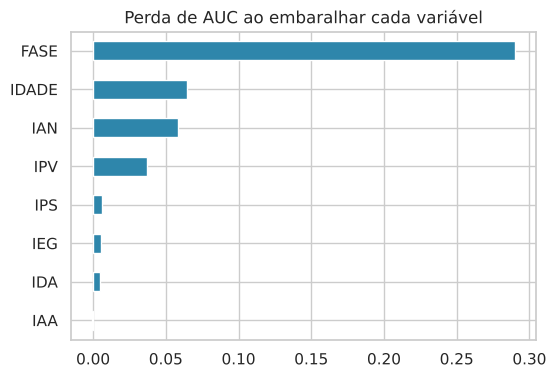

In [18]:
importancia = permutation_importance(modelo, teste[VARIAVEIS], teste['DEFASADO_PROX'],
                                     scoring='roc_auc', n_repeats=20, random_state=42)
pd.Series(importancia.importances_mean, index=VARIAVEIS).sort_values().plot(
    kind='barh', figsize=(6, 4), color='#2E86AB')
plt.title('Perda de AUC ao embaralhar cada variável')
plt.show()

**Leitura:** fase e idade são, de longe, as variáveis mais importantes. Faz sentido: a fase ideal depende da idade escolar, então um aluno que envelhece sem avançar de fase entra em defasagem. Os indicadores socioemocionais e de desempenho acrescentam pouco à previsão de um ano para o outro.

**Consequência prática:** o principal fator de risco é a **progressão de fase** em relação à idade. Os alunos sinalizados são, em grande parte, os que estão perto de "ficar para trás" no calendário escolar.

## 3.6 Modelo final e ranking de risco para 2025

Validado o método, o modelo final é treinado com as duas passagens (2022 → 2023 e 2023 → 2024) e aplicado aos alunos de 2024 para estimar o risco em 2025.

In [19]:
modelo_final = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)
modelo_final.fit(pares[VARIAVEIS], pares['DEFASADO_PROX'])
joblib.dump({'modelo': modelo_final, 'variaveis': VARIAVEIS}, 'modelo_risco.joblib')

alunos_2024 = base[base['ANO'] == 2024].copy()
alunos_2024['PROB_DEFASAGEM_2025'] = modelo_final.predict_proba(alunos_2024[VARIAVEIS])[:, 1]
alunos_2024['FAIXA_RISCO'] = pd.cut(alunos_2024['PROB_DEFASAGEM_2025'], [0, 0.35, 0.6, 1],
                                    labels=['Baixo', 'Médio', 'Alto'], include_lowest=True)

display(pd.crosstab(alunos_2024['NIVEL_DEFASAGEM'], alunos_2024['FAIXA_RISCO']))

FAIXA_RISCO,Baixo,Médio,Alto
NIVEL_DEFASAGEM,,,
Moderada,46,68,417
Sem defasagem,444,110,68
Severa,0,0,3


# 4. Exportando as bases do app

In [20]:
base.to_csv('dados_limpos.csv', index=False)

colunas_ranking = ['RA', 'FASE', 'IDADE', 'PEDRA', 'NIVEL_DEFASAGEM', 'DEFASAGEM',
                   'IDA', 'IEG', 'IPS', 'IPV', 'PROB_DEFASAGEM_2025', 'FAIXA_RISCO']
(alunos_2024[colunas_ranking]
    .sort_values('PROB_DEFASAGEM_2025', ascending=False)
    .to_csv('ranking_risco_2025.csv', index=False))